# TP 03: Decision tree
---
### Name: Felipe Fazio da Costa
### 15/10/2026
---
### Machine Learning corse

## 0. Import of the libary:

In [28]:
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import math

## 1. Preparatin of the data:

In [2]:
# Load dos dados de iris
iris = load_iris()

# Set do dados para utilização sobre o ML
dataset = pd.DataFrame(data=iris.data, columns=iris.feature_names)

dataset['especies'] = pd.Categorical.from_codes(iris.target, iris.target_names)

print(dataset)
print(dataset.head())
print(dataset.info())

     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                  5.1               3.5                1.4               0.2   
1                  4.9               3.0                1.4               0.2   
2                  4.7               3.2                1.3               0.2   
3                  4.6               3.1                1.5               0.2   
4                  5.0               3.6                1.4               0.2   
..                 ...               ...                ...               ...   
145                6.7               3.0                5.2               2.3   
146                6.3               2.5                5.0               1.9   
147                6.5               3.0                5.2               2.0   
148                6.2               3.4                5.4               2.3   
149                5.9               3.0                5.1               1.8   

      especies  
0       se

In [3]:
# Variables quantitatives
print(dataset.describe())

# Variables qualitatives
counts = dataset['especies'].value_counts()

print(counts)

       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)  
count        150.000000  
mean           1.199333  
std            0.762238  
min            0.100000  
25%            0.300000  
50%            1.300000  
75%            1.800000  
max            2.500000  
especies
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


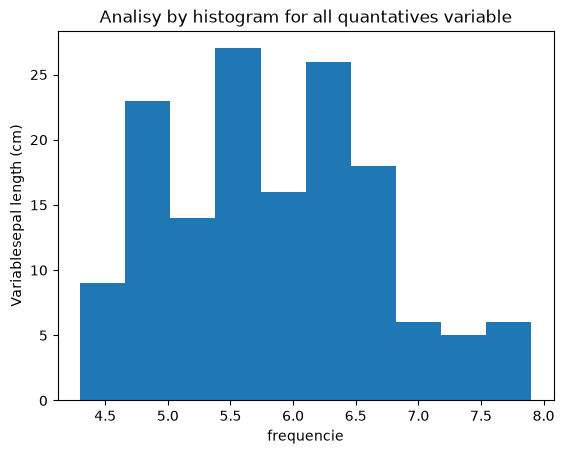

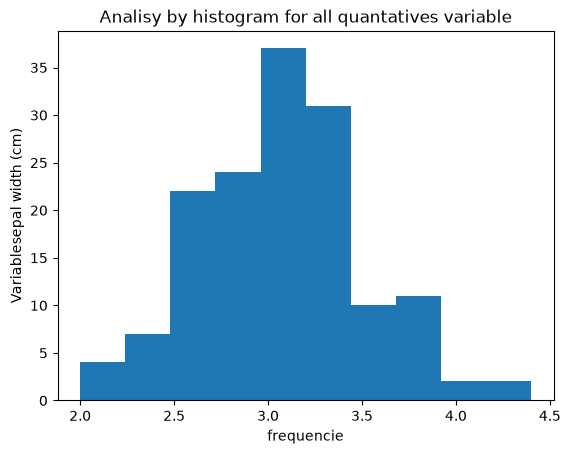

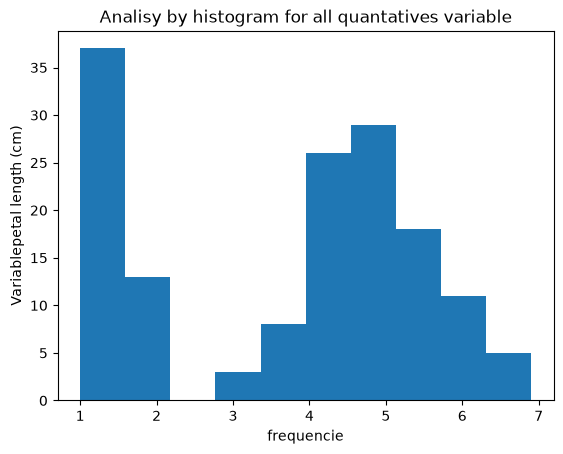

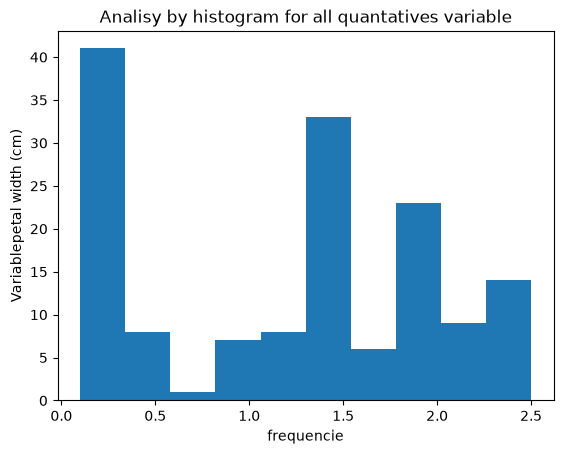

In [4]:
for col in dataset.columns[:4]:
    plt.hist(dataset[col])
    plt.xlabel("frequencie")
    plt.ylabel("Variable" + col)
    plt.title("Analisy by histogram for all quantatives variable")
    plt.show()

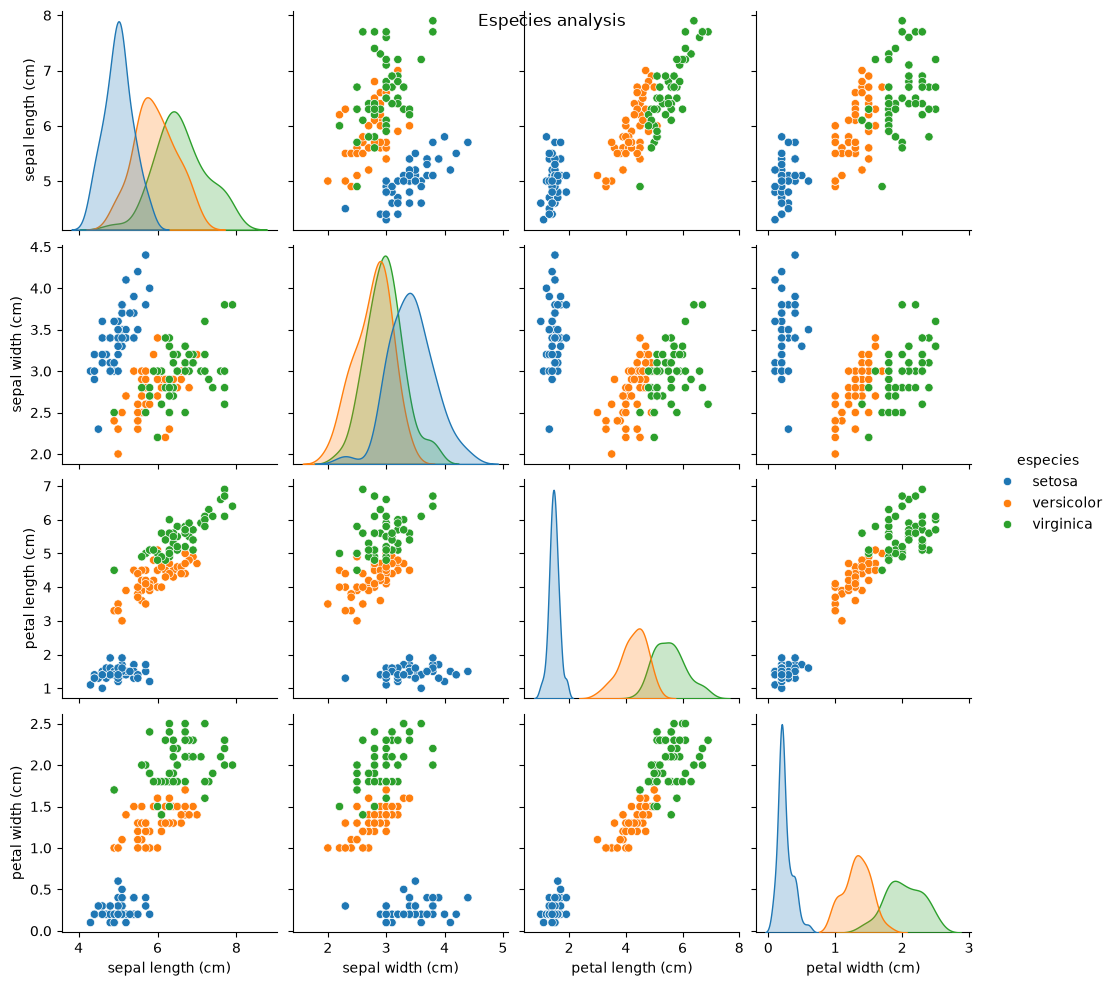

In [5]:
sns.pairplot(dataset, hue='especies', diag_kind='kde')
plt.suptitle("Especies analysis")
plt.show()

## 2. Decision trees

In [6]:
dataset_petal = dataset.iloc[:, [2,3]]

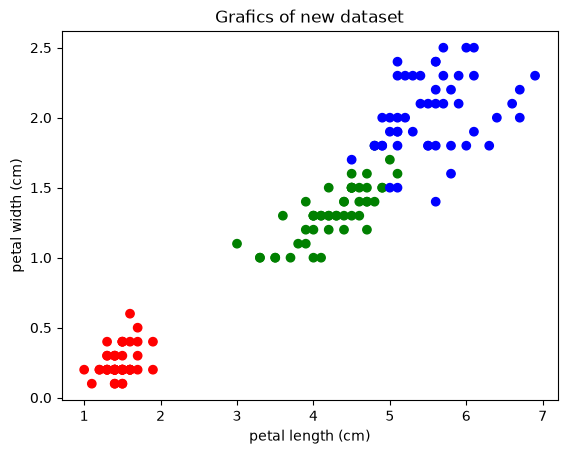

In [7]:
colors = dataset['especies'].map({'setosa':'red', 'versicolor':'green', 'virginica':'blue'})

plt.scatter(dataset_petal.iloc[:, 0], dataset_petal.iloc[:, 1], c=colors)

plt.title("Grafics of new dataset")
plt.xlabel(dataset_petal.columns[0])
plt.ylabel(dataset_petal.columns[1])
plt.show()

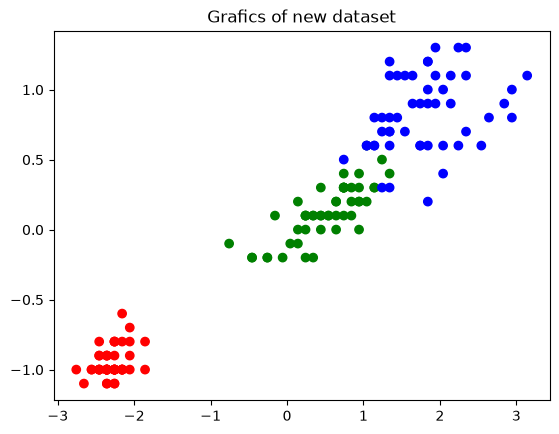

In [34]:
petal_length = np.array(dataset_petal.iloc[:, 0])
petal_width = np.array(dataset_petal.iloc[:, 1])

# We got the Random center values is the x' = x - x_mean
petal_length = petal_length - np.mean(petal_length)
petal_width = petal_width - np.mean(petal_width)

plt.close("all")
colors = dataset['especies'].map({'setosa':'red', 'versicolor':'green', 'virginica':'blue'})

plt.scatter(petal_length, petal_width, c=colors)

plt.title("Grafics of new dataset")
plt.show()

In [37]:
# Inercie = 1/n * Sum(||xi - x_mean||^2)

X = np.array([petal_length, petal_width]).T
n = X.shape[0]
inertie = (1 / n) * np.sum(np.diag(X.T @ X))
print(inertie)

3.6726355555555563


In [42]:
# Linear corelation cofficient: rjj = cov(xj, xj')/ sig_j * sig_j'

cov = (petal_length.T @ petal_width) / n
print(cov)

corr = cov / (np.std(petal_length) * np.std(petal_width))
print(corr)
print(np.corrcoef(petal_length, petal_width))

1.2869720000000002
0.9628654314027961
[[1.         0.96286543]
 [0.96286543 1.        ]]


In [44]:
# Creation of the function impurete in function the p

def impurete(p):
    return 1 - np.sum(p**2)

p_test = np.array([
[0.5, 0.5],
[0, 1],
[0.3, 0.7]
])
[print(impurete(p)) for p in p_test]

0.5
0.0
0.42000000000000004


[None, None, None]

In [45]:
class Noeud:
    def __init__(self, X, y, classes):
        self.X = np.array(X)
        self.y = np.array(y)
        self.n, self.p = self.X.shape
        self.classes = classes

In [48]:
petal_length = np.array(dataset.iloc[:, 2])
petal_width = np.array(dataset.iloc[:, 3])
petal_length = (petal_length - np.mean(petal_length))
petal_width = (petal_width - np.mean(petal_width))
X = np.array([petal_length, petal_width]).T
S = Noeud(X, dataset['especies'], np.unique(dataset['especies']))

In [51]:
def gain(S, j, v):
    def proportions(S):
        return np.array([np.sum(S.y == classe) / S.n for classe in S.classes])
    n = S.X.shape[0]
    n_gauche = np.sum(S.X[:, j] <= v)
    n_droite = np.sum(S.X[:, j] > v)
    p = proportions(S)
    p_gauche = proportions(Noeud(S.X[S.X[:, j] <= v], S.y[S.X[:, j] <= v], S.classes))
    p_droite = proportions(Noeud(S.X[S.X[:, j] > v], S.y[S.X[:, j] > v], S.classes))
    return impurete(p) - ((n_gauche/n) * impurete(p_gauche) + (n_droite/n) * impurete(p_droite))

print(gain(S, 0, -1))

0.3333333333333334


In [53]:
def optimise_gain(S):
    gain_max = 0
    j_star = 0
    v_star = 0
    for j in range(S.X.shape[1]):
        valeurs = np.sort(list(set(S.X[:,j])))
        for n in range(len(valeurs) - 1):
            v = (valeurs[n] + valeurs[n + 1]) / 2
            gain_actuel = gain(S, j, v)
            if gain_actuel > gain_max:
                gain_max = gain_actuel
                j_star = j
                v_star = v

    return j_star, v_star, gain_max
print(optimise_gain(S))

(0, np.float64(-1.3080000000000005), np.float64(0.3333333333333334))


In [54]:
class Noeud:
    def __init__(self, X, y, classes, j=0, v=0, gauche=None, droite=None):
        self.X = np.array(X)
        self.y = np.array(y)
        self.n, self.p = self.X.shape
        self.classes = classes
        self.j = j
        self.v = v
        self.gauche=gauche
        self.droite=droite

In [56]:
def arbre_recursif(S):
    S.j, S.v, gain = optimise_gain(S)
    if gain == 0:
        return S
    S.gauche = Noeud(S.X[S.X[:, S.j] <= S.v], S.y[S.X[:, S.j] <= S.v], S.classes)
    S.droite = Noeud(S.X[S.X[:, S.j] > S.v], S.y[S.X[:, S.j] > S.v], S.classes)
    arbre_recursif(S.gauche)
    arbre_recursif(S.droite)
    return S
arbre_recursif(S)

In [59]:
def print_tree(S, depth=0):
    indent = " " * depth
    if S.gauche is None:
        y_list = list(S.y)
        print(f"{indent}Leaf: class={max(set(y_list), key=y_list.count)}")
    else:
        print(f"{indent}Feature[{S.j}] <= {S.v}")
        print_tree(S.gauche, depth+1)
        print_tree(S.droite, depth+1)
print_tree(S)

Feature[0] <= -1.3080000000000005
 Leaf: class=setosa
 Feature[1] <= 0.5506666666666664
  Feature[0] <= 1.1919999999999997
   Feature[1] <= 0.45066666666666644
    Leaf: class=versicolor
    Leaf: class=virginica
   Feature[1] <= 0.35066666666666646
    Leaf: class=virginica
    Feature[0] <= 1.6919999999999993
     Leaf: class=versicolor
     Leaf: class=virginica
  Feature[0] <= 1.0919999999999996
   Leaf: class=virginica
   Leaf: class=virginica


In [63]:
# Contructing the class prediction for the X_test

X_test = [[-2, -0.7], # setosa
         [0.6, -0.1], # versicolor
            [1.7, 1]] # virginica

def prediction(S, x):
    if S.gauche is None:
        return max(set(list(S.y)), key=list(S.y).count)
    if x[S.j] <= S.v:
        return prediction(S.gauche, x)
    else:
        return prediction(S.droite, x)

for x in X_test:
    print(prediction(S, x))

setosa
versicolor
virginica


In [ ]:
# Construction of the class MonArbre for generalize for all cases

